# Langkah 3 Anggota A — Exploratory Data Analysis (EDA) RAVDESS

EDA adalah tahap **mengenal data sebelum membangun model**: melihat bentuk distribusinya, mendengar dan melihat sinyalnya, serta mencari hal yang perlu diperhatikan saat preprocessing.

Notebook ini menghasilkan:

| No | Output | Isi |
| --- | --- | --- |
| 1 | `figures/eda/eda_01_distribusi_kelas.png` | Jumlah file per emosi dan intensitas |
| 2 | `figures/eda/eda_02_durasi.png` | Histogram durasi semua file |
| 3 | `figures/eda/eda_03_durasi_per_emosi.png` | Sebaran durasi per emosi |
| 4 | `figures/eda/eda_04_contoh_aktor01.png` | Waveform + mel-spectrogram tiap emosi (aktor 1, laki-laki) |
| 5 | `figures/eda/eda_05_contoh_aktor02.png` | Sama, untuk aktor 2 (perempuan) |
| 6 | `data/eda_audio_stats.csv` | Level suara dan durasi hening setiap file |
| 7 | `figures/eda/eda_06_energi_per_emosi.png` | Energi (RMS dB) per emosi |
| 8 | `figures/eda/eda_07_hening_dan_puncak.png` | Durasi hening dan puncak amplitudo |
| 9 | `figures/eda/eda_summary.txt` | Ringkasan angka temuan EDA |

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`. Sel 6 (analisis semua file) butuh beberapa menit; hasilnya disimpan, sehingga kalau dijalankan ulang akan langsung dimuat.

**Prasyarat:** langkah 1 selesai (`metadata.csv` dan folder `ravdess_speech` ada di Drive).

## Sel 1 — Persiapan

Menghubungkan Drive, memuat `metadata.csv`, membuat folder gambar, dan mengatur gaya grafik.
Sel ini **berdiri sendiri** (memuat data dari Drive), jadi aman dijalankan di sesi Colab baru.

`TARGET_SR = 16000` adalah sample rate yang direncanakan untuk preprocessing. EDA memakai nilai yang sama supaya yang Anda lihat sama dengan yang nanti diolah.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
AUDIO_DIR = os.path.join(DATA_DIR, 'raw', 'ravdess_speech')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'eda')
os.makedirs(FIG_DIR, exist_ok=True)

meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))
TARGET_SR = 16000
TOP_DB = 30  # ambang trim hening yang direncanakan untuk preprocessing

# Urutan emosi tetap (sesuai kode RAVDESS) dan warna konsisten di semua grafik
EMOSI = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
BIRU, ORANYE = '#2a78d6', '#eb6834'
TEKS, TEKS2, GRID = '#0b0b0b', '#52514e', '#e4e3df'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.edgecolor': TEKS2, 'axes.labelcolor': TEKS, 'text.color': TEKS,
    'xtick.color': TEKS2, 'ytick.color': TEKS2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

def simpan(fig, nama):
    path = os.path.join(FIG_DIR, nama)
    fig.savefig(path)
    print('Tersimpan:', path)

print('Jumlah file di metadata:', len(meta))
print('Folder gambar:', FIG_DIR)

Mounted at /content/drive
Jumlah file di metadata: 1440
Folder gambar: /content/drive/MyDrive/project07/figures/eda


## Sel 2 — Distribusi kelas

**Pertanyaan:** apakah jumlah data tiap emosi seimbang?

Grafik batang dikelompokkan per emosi, dibedakan menurut intensitas. Yang diharapkan: neutral hanya punya batang *normal*, sehingga totalnya separuh emosi lain.

**Mengapa penting:** kelas yang lebih sedikit cenderung lebih jarang ditebak model. Inilah alasan proyek memakai **macro F1** (rata-rata F1 semua kelas dengan bobot sama) dan `class_weight='balanced'`.

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_01_distribusi_kelas.png


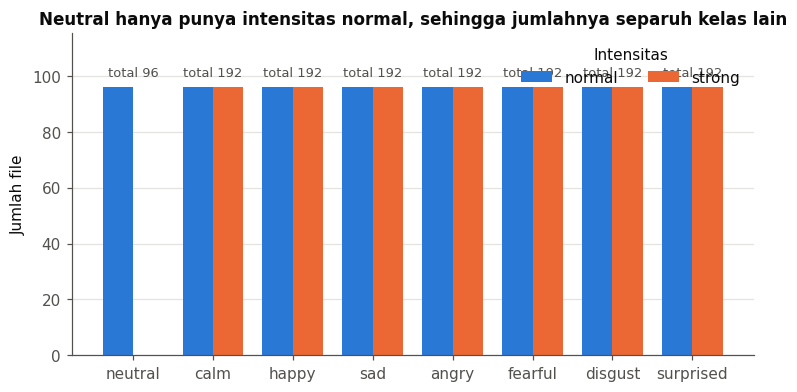

intensity,normal,strong,total
emotion,,,
neutral,96,0,96
calm,96,96,192
happy,96,96,192
sad,96,96,192
angry,96,96,192
fearful,96,96,192
disgust,96,96,192
surprised,96,96,192


In [2]:
hitung = (meta.groupby(['emotion', 'intensity']).size()
          .unstack(fill_value=0).reindex(EMOSI))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(EMOSI))
w = 0.38
b1 = ax.bar(x - w/2, hitung['normal'], w, color=BIRU, label='normal')
b2 = ax.bar(x + w/2, hitung['strong'], w, color=ORANYE, label='strong')
for i, emo in enumerate(EMOSI):
    total = hitung.loc[emo].sum()
    ax.text(i, max(hitung.loc[emo]) + 4, f'total {total}', ha='center', fontsize=8.5, color=TEKS2)
ax.set_xticks(x, EMOSI)
ax.set_ylabel('Jumlah file')
ax.set_ylim(0, hitung.values.max() * 1.2)
ax.set_title('Neutral hanya punya intensitas normal, sehingga jumlahnya separuh kelas lain')
ax.legend(title='Intensitas', frameon=False, loc='upper right', ncol=2)
ax.grid(axis='x', visible=False)
simpan(fig, 'eda_01_distribusi_kelas.png')
plt.show()
display(hitung.assign(total=hitung.sum(axis=1)))

## Sel 3 — Durasi rekaman

**Pertanyaan:** seberapa panjang rekamannya, dan apakah durasi berbeda antaremosi?

- Grafik pertama: histogram semua 1.440 file. Garis putus-putus = median.
- Grafik kedua: sebaran durasi per emosi (kotak = 50% data di tengah, garis tengah = median, titik = file ekstrem).

**Mengapa penting:** kalau durasi sangat berbeda antaremosi, model bisa "curang" menebak emosi dari panjang rekaman, bukan dari cara bicara. Fitur proyek berupa statistik rata-rata/simpangan per file, sehingga relatif tidak terpengaruh panjang rekaman, tetapi temuan ini tetap perlu dicatat.

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_02_durasi.png


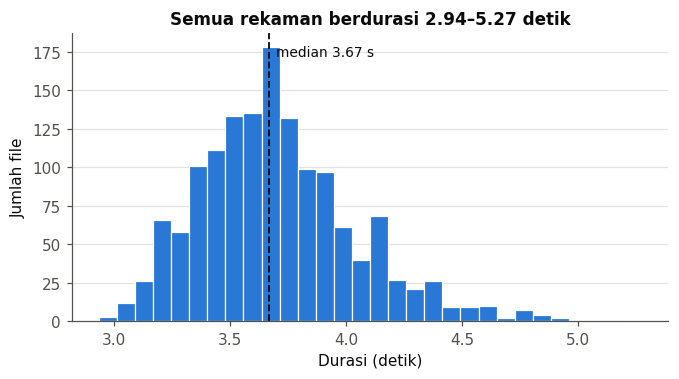

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_03_durasi_per_emosi.png


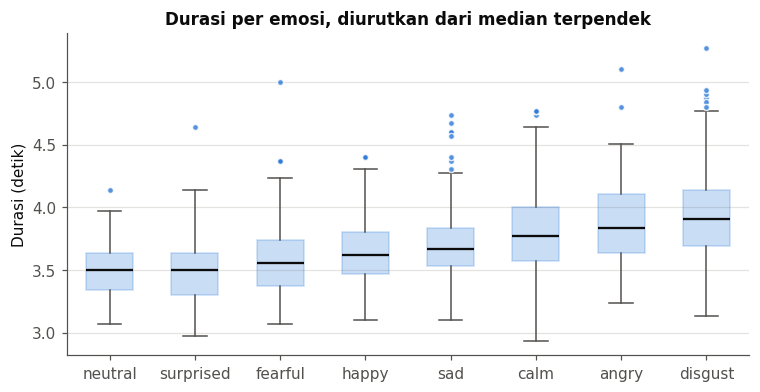

,count,mean,std,min,25%,50%,75%,max
emotion,,,,,,,,
neutral,96.0,3.50,0.21,3.07,3.34,3.50,3.64,4.14
calm,192.0,3.80,0.33,2.94,3.57,3.77,4.00,4.77
happy,192.0,3.64,0.26,3.10,3.47,3.62,3.80,4.40
sad,192.0,3.69,0.29,3.10,3.53,3.67,3.84,4.74
angry,192.0,3.87,0.32,3.24,3.64,3.84,4.10,5.11
fearful,192.0,3.57,0.29,3.07,3.37,3.55,3.74,5.00
disgust,192.0,3.94,0.38,3.14,3.70,3.90,4.14,5.27
surprised,192.0,3.49,0.24,2.97,3.30,3.50,3.64,4.64


In [3]:
d = meta['duration_s']
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(d, bins=30, color=BIRU, edgecolor='white', linewidth=0.8)
ax.axvline(d.median(), color=TEKS, linestyle='--', linewidth=1.2)
ax.text(d.median() + 0.03, ax.get_ylim()[1] * 0.92, f'median {d.median():.2f} s', fontsize=9, color=TEKS)
ax.set_xlabel('Durasi (detik)')
ax.set_ylabel('Jumlah file')
ax.set_title(f'Semua rekaman berdurasi {d.min():.2f}–{d.max():.2f} detik')
ax.grid(axis='x', visible=False)
simpan(fig, 'eda_02_durasi.png')
plt.show()

urut = meta.groupby('emotion')['duration_s'].median().reindex(EMOSI).sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(8, 3.8))
data = [meta.loc[meta['emotion'] == e, 'duration_s'] for e in urut]
bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                medianprops=dict(color=TEKS, linewidth=1.5),
                flierprops=dict(marker='o', markersize=4, markerfacecolor=BIRU, markeredgecolor='white', alpha=0.8),
                whiskerprops=dict(color=TEKS2), capprops=dict(color=TEKS2))
for kotak in bp['boxes']:
    kotak.set(facecolor=BIRU, alpha=0.25, edgecolor=BIRU)
ax.set_xticks(range(1, len(urut) + 1), urut)
ax.set_ylabel('Durasi (detik)')
ax.set_title('Durasi per emosi, diurutkan dari median terpendek')
ax.grid(axis='x', visible=False)
simpan(fig, 'eda_03_durasi_per_emosi.png')
plt.show()

display(meta.groupby('emotion')['duration_s'].describe().reindex(EMOSI).round(2))

## Sel 4 — Contoh waveform dan mel-spectrogram tiap emosi

**Pertanyaan:** seperti apa bentuk sinyal tiap emosi, dan apa bedanya?

Untuk perbandingan yang adil, semua contoh berasal dari **aktor yang sama, kalimat yang sama, pengulangan yang sama**. Intensitas *strong* dipilih agar perbedaan emosi lebih jelas (neutral memakai *normal* karena tidak punya *strong*).

Cara membaca setiap baris:
- **Kiri — waveform:** amplitudo sinyal terhadap waktu. Semakin tinggi simpangan, semakin keras suara. Skala vertikal sama untuk semua baris, sehingga keras-lembut antaremosi bisa dibandingkan langsung.
- **Kanan — mel-spectrogram:** energi tiap frekuensi (sumbu vertikal, skala mel menyerupai pendengaran manusia) terhadap waktu. Warna terang = energi tinggi. Garis-garis horizontal sejajar di bagian bawah adalah **harmonik** dari nada suara (pitch); semakin renggang dan tinggi letaknya, semakin tinggi nadanya. Skala warna sama untuk semua baris.

Perhatikan misalnya: *angry* dan *happy* biasanya lebih keras dan energinya menyebar ke frekuensi tinggi; *sad* dan *calm* lebih lembut.

Ubah `AKTOR_CONTOH` jika ingin melihat aktor lain.

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_04_contoh_aktor01.png


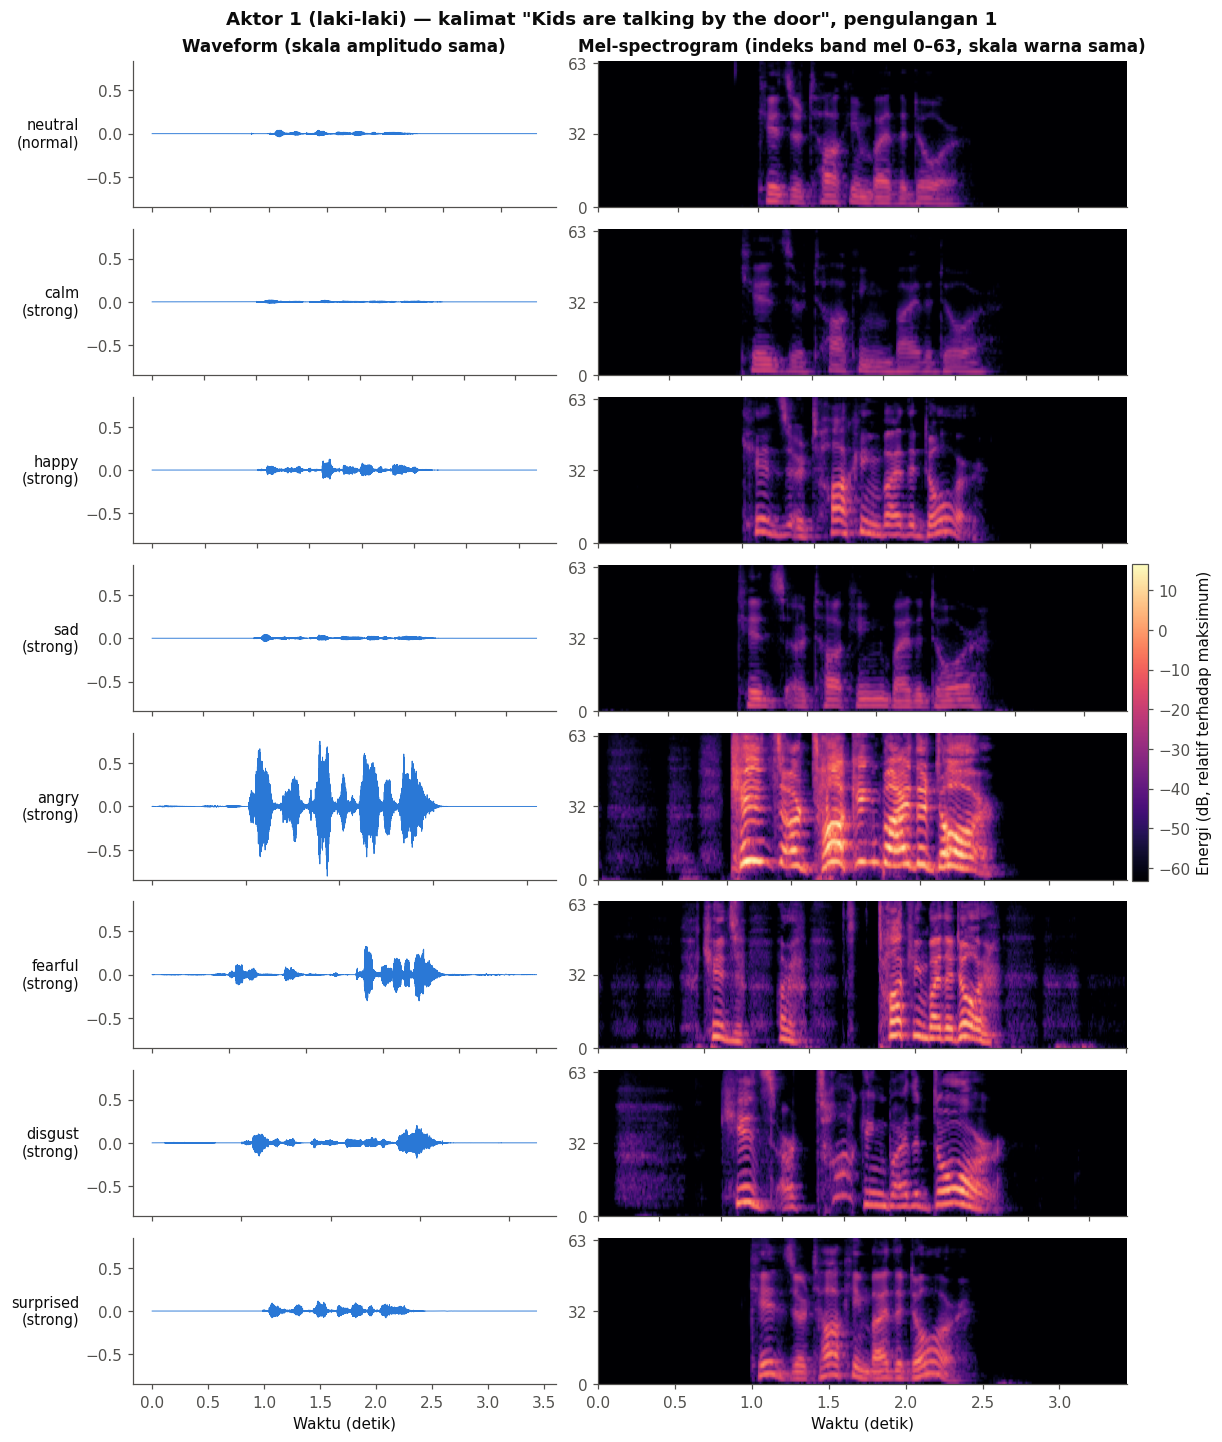

,emotion,intensity,file
0,neutral,normal,Actor_01/03-01-01-01-01-01-01.wav
8,calm,strong,Actor_01/03-01-02-02-01-01-01.wav
16,happy,strong,Actor_01/03-01-03-02-01-01-01.wav
24,sad,strong,Actor_01/03-01-04-02-01-01-01.wav
32,angry,strong,Actor_01/03-01-05-02-01-01-01.wav
40,fearful,strong,Actor_01/03-01-06-02-01-01-01.wav
48,disgust,strong,Actor_01/03-01-07-02-01-01-01.wav
56,surprised,strong,Actor_01/03-01-08-02-01-01-01.wav


In [4]:
def contoh_per_emosi(aktor, statement=1, repetition=1):
    pilih = meta[(meta['actor'] == aktor) & (meta['statement'] == statement) & (meta['repetition'] == repetition)]
    baris = []
    for e in EMOSI:
        kand = pilih[pilih['emotion'] == e]
        kuat = kand[kand['intensity'] == 'strong']
        baris.append((kuat if len(kuat) else kand).iloc[0])
    return pd.DataFrame(baris)

def plot_contoh(aktor, nama_file):
    contoh = contoh_per_emosi(aktor)
    sinyal = []
    for _, r in contoh.iterrows():
        y, _ = librosa.load(os.path.join(AUDIO_DIR, r['file']), sr=TARGET_SR, mono=True)
        sinyal.append(y)
    amp = max(np.abs(y).max() for y in sinyal)
    mels = [librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=TARGET_SR, n_fft=512, hop_length=160, n_mels=64))
            for y in sinyal]
    vmax = max(m.max() for m in mels)
    vmin = vmax - 80

    fig, axes = plt.subplots(len(EMOSI), 2, figsize=(11, 13), gridspec_kw={'width_ratios': [1, 1.25]},
                             layout='constrained')
    for i, ((_, r), y, m) in enumerate(zip(contoh.iterrows(), sinyal, mels)):
        t = np.arange(len(y)) / TARGET_SR
        aw, asp = axes[i, 0], axes[i, 1]
        aw.plot(t, y, color=BIRU, linewidth=0.6)
        aw.set_ylim(-amp * 1.05, amp * 1.05)
        aw.set_ylabel(f"{r['emotion']}\n({r['intensity']})", rotation=0, ha='right', va='center', fontsize=9.5)
        aw.grid(False)
        dur = len(y) / TARGET_SR
        im = asp.imshow(m, origin='lower', aspect='auto', cmap='magma', vmin=vmin, vmax=vmax,
                        extent=[0, dur, 0, m.shape[0]])
        asp.grid(False)
        asp.set_yticks([0, 32, 63], ['0', '32', '63'])
        if i < len(EMOSI) - 1:
            aw.set_xticklabels([]); asp.set_xticklabels([])
    axes[-1, 0].set_xlabel('Waktu (detik)')
    axes[-1, 1].set_xlabel('Waktu (detik)')
    axes[0, 0].set_title('Waveform (skala amplitudo sama)')
    axes[0, 1].set_title('Mel-spectrogram (indeks band mel 0–63, skala warna sama)')
    gender = 'laki-laki' if contoh['gender'].iloc[0] == 'male' else 'perempuan'
    fig.suptitle(f'Aktor {aktor} ({gender}) — kalimat "Kids are talking by the door", pengulangan 1',
                 fontsize=12, fontweight='bold')
    cbar = fig.colorbar(im, ax=axes[:, 1], fraction=0.03, pad=0.01)
    cbar.set_label('Energi (dB, relatif terhadap maksimum)')
    simpan(fig, nama_file)
    plt.show()
    return contoh[['emotion', 'intensity', 'file']]

AKTOR_CONTOH = 1
plot_contoh(AKTOR_CONTOH, 'eda_04_contoh_aktor01.png')

### Dengarkan contoh yang sama

Bandingkan apa yang Anda dengar dengan gambar di atas.

In [5]:
from IPython.display import Audio, display
for _, r in contoh_per_emosi(AKTOR_CONTOH).iterrows():
    print(r['emotion'], f"({r['intensity']})")
    display(Audio(os.path.join(AUDIO_DIR, r['file'])))

Output hidden; open in https://colab.research.google.com to view.

## Sel 5 — Contoh dari aktor perempuan

Sama seperti Sel 4, untuk aktor 2 (perempuan). Bandingkan dengan aktor 1: suara perempuan umumnya bernada lebih tinggi, sehingga harmonik di mel-spectrogram tampak lebih renggang. Ini menunjukkan bahwa **nada suara dipengaruhi gender, bukan hanya emosi** — salah satu alasan uji stabilitas lintas speaker penting.

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_05_contoh_aktor02.png


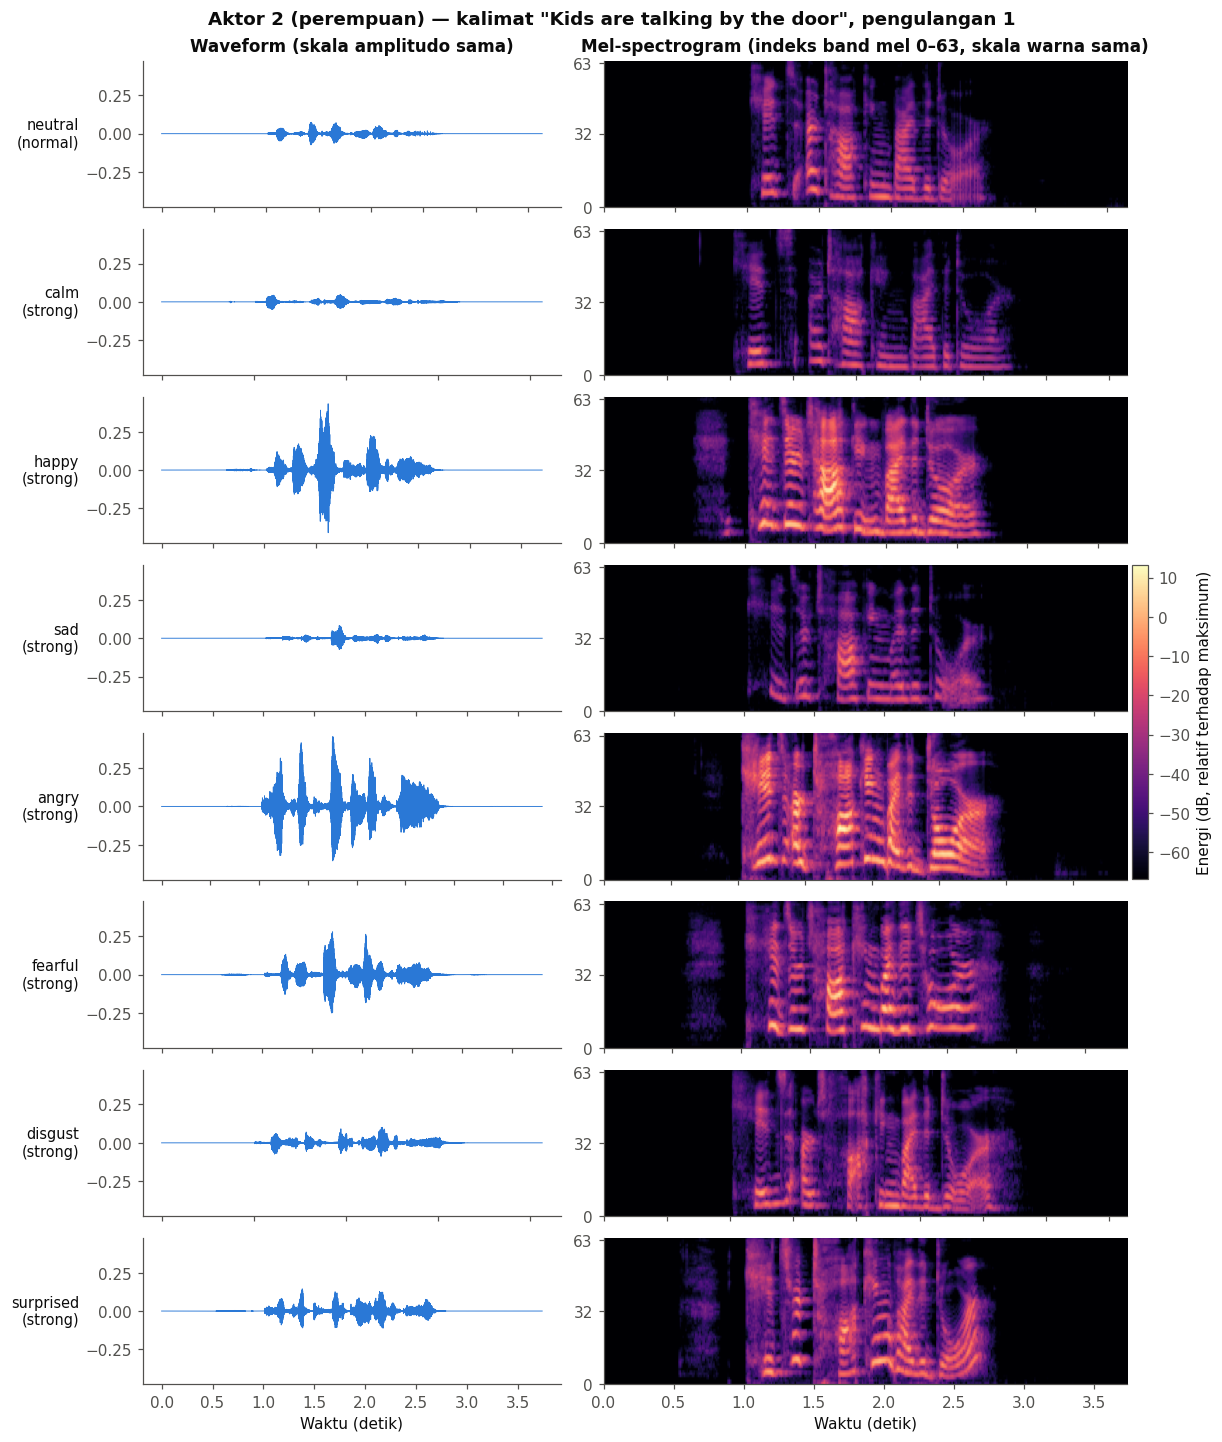

,emotion,intensity,file
60,neutral,normal,Actor_02/03-01-01-01-01-01-02.wav
68,calm,strong,Actor_02/03-01-02-02-01-01-02.wav
76,happy,strong,Actor_02/03-01-03-02-01-01-02.wav
84,sad,strong,Actor_02/03-01-04-02-01-01-02.wav
92,angry,strong,Actor_02/03-01-05-02-01-01-02.wav
100,fearful,strong,Actor_02/03-01-06-02-01-01-02.wav
108,disgust,strong,Actor_02/03-01-07-02-01-01-02.wav
116,surprised,strong,Actor_02/03-01-08-02-01-01-02.wav


In [6]:
plot_contoh(2, 'eda_05_contoh_aktor02.png')

## Sel 6 — Analisis level suara dan hening untuk semua file

**Pertanyaan:** seberapa keras rekamannya, dan berapa lama bagian hening di awal dan akhir?

Untuk setiap file (dimuat mono, 16 kHz), sel ini menghitung:

| Kolom | Arti |
| --- | --- |
| `peak` | Amplitudo tertinggi (skala 0–1). Kecil = rekaman pelan |
| `rms_db` | Energi rata-rata dalam desibel (dB). Lebih mendekati 0 = lebih keras |
| `speech_s` | Durasi setelah hening awal/akhir dipotong (`top_db=30`) |
| `lead_sil_s`, `trail_sil_s` | Lama hening di awal dan akhir (detik) |
| `sil_ratio` | Proporsi hening terhadap durasi total |

**Mengapa penting:** hasil ini dipakai untuk memastikan parameter preprocessing (trim hening dan normalisasi) masuk akal, dan menjadi bahan diskusi dengan Anggota B.

Butuh sekitar 3–8 menit. Hasil disimpan ke `data/eda_audio_stats.csv`; jika file itu sudah ada, sel langsung memuatnya.

In [7]:
STATS_PATH = os.path.join(DATA_DIR, 'eda_audio_stats.csv')

if os.path.exists(STATS_PATH):
    stats = pd.read_csv(STATS_PATH)
    print('Dimuat dari file yang sudah ada:', STATS_PATH)
else:
    baris = []
    for i, r in meta.iterrows():
        y, _ = librosa.load(os.path.join(AUDIO_DIR, r['file']), sr=TARGET_SR, mono=True)
        total = len(y) / TARGET_SR
        _, (awal, akhir) = librosa.effects.trim(y, top_db=TOP_DB)
        rms = np.sqrt(np.mean(y ** 2))
        baris.append({
            'file': r['file'],
            'peak': float(np.abs(y).max()),
            'rms_db': float(20 * np.log10(rms + 1e-10)),
            'speech_s': (akhir - awal) / TARGET_SR,
            'lead_sil_s': awal / TARGET_SR,
            'trail_sil_s': total - akhir / TARGET_SR,
        })
        if (i + 1) % 200 == 0:
            print(f'  {i + 1} / {len(meta)} file')
    stats = pd.DataFrame(baris)
    stats.to_csv(STATS_PATH, index=False)
    print('Tersimpan:', STATS_PATH)

stats = meta[['file', 'actor', 'gender', 'emotion', 'intensity', 'duration_s']].merge(stats, on='file')
stats['sil_ratio'] = (stats['lead_sil_s'] + stats['trail_sil_s']) / stats['duration_s']
stats[['peak', 'rms_db', 'speech_s', 'lead_sil_s', 'trail_sil_s', 'sil_ratio']].describe().round(3)

  200 / 1440 file
  400 / 1440 file
  600 / 1440 file
  800 / 1440 file
  1000 / 1440 file
  1200 / 1440 file
  1400 / 1440 file
Tersimpan: /content/drive/MyDrive/project07/data/eda_audio_stats.csv


,peak,rms_db,speech_s,lead_sil_s,trail_sil_s,sil_ratio
count,1440.000,1440.000,1440.000,1440.000,1440.000,1440.000
mean,0.175,-39.778,1.896,0.930,0.875,0.491
std,0.212,9.096,0.420,0.162,0.204,0.084
min,0.005,-63.748,1.152,0.000,0.000,0.009
25%,0.047,-46.083,1.600,0.960,0.867,0.465
50%,0.097,-40.141,1.792,0.960,0.921,0.512
75%,0.201,-33.952,2.112,0.992,0.967,0.543
max,1.052,-16.369,4.248,1.376,1.347,0.615


## Sel 7 — Energi per emosi, hening, dan puncak amplitudo

- **Grafik energi per emosi:** apakah emosi tertentu lebih keras? Jika ya, fitur energi (RMS) kemungkinan berguna — dan mungkin akan dipilih oleh simulated annealing.
- **Grafik hening:** berapa banyak hening yang akan dibuang oleh trim.
- **Grafik puncak amplitudo:** apakah volume rekaman bervariasi. Jika ya, normalisasi puncak perlu dilakukan sebelum ekstraksi fitur.

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_06_energi_per_emosi.png


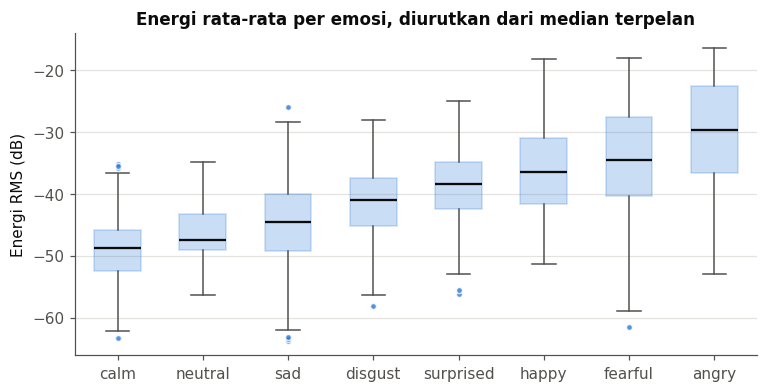

Tersimpan: /content/drive/MyDrive/project07/figures/eda/eda_07_hening_dan_puncak.png


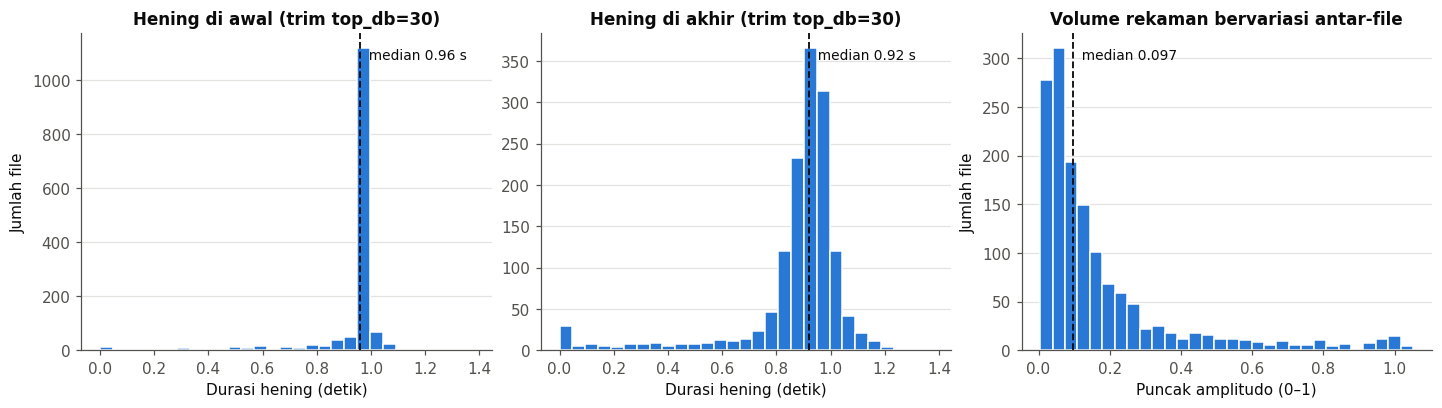

,rms_db,peak,sil_ratio
emotion,,,
neutral,-47.384,0.043,0.534
calm,-48.782,0.031,0.486
happy,-36.389,0.156,0.525
sad,-44.558,0.056,0.508
angry,-29.714,0.361,0.500
fearful,-34.553,0.166,0.529
disgust,-40.926,0.089,0.473
surprised,-38.322,0.118,0.539


,rms_db,peak,duration_s
gender,,,
female,-39.090,0.100,3.704
male,-40.908,0.094,3.570


In [8]:
urut = stats.groupby('emotion')['rms_db'].median().reindex(EMOSI).sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot([stats.loc[stats['emotion'] == e, 'rms_db'] for e in urut], patch_artist=True, widths=0.55,
                medianprops=dict(color=TEKS, linewidth=1.5),
                flierprops=dict(marker='o', markersize=4, markerfacecolor=BIRU, markeredgecolor='white', alpha=0.8),
                whiskerprops=dict(color=TEKS2), capprops=dict(color=TEKS2))
for kotak in bp['boxes']:
    kotak.set(facecolor=BIRU, alpha=0.25, edgecolor=BIRU)
ax.set_xticks(range(1, len(urut) + 1), urut)
ax.set_ylabel('Energi RMS (dB)')
ax.set_title('Energi rata-rata per emosi, diurutkan dari median terpelan')
ax.grid(axis='x', visible=False)
simpan(fig, 'eda_06_energi_per_emosi.png')
plt.show()

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
batas = max(stats['lead_sil_s'].max(), stats['trail_sil_s'].max())
bins = np.linspace(0, batas, 30)
for ax_, kol, judul in [(a0, 'lead_sil_s', 'Hening di awal'), (a1, 'trail_sil_s', 'Hening di akhir')]:
    ax_.hist(stats[kol], bins=bins, color=BIRU, edgecolor='white')
    ax_.axvline(stats[kol].median(), color=TEKS, linestyle='--', linewidth=1.2)
    ax_.text(stats[kol].median(), ax_.get_ylim()[1] * 0.92, f'  median {stats[kol].median():.2f} s', fontsize=9)
    ax_.set_xlabel('Durasi hening (detik)')
    ax_.set_title(f'{judul} (trim top_db={TOP_DB})')
    ax_.grid(axis='x', visible=False)
a0.set_ylabel('Jumlah file')
a2.hist(stats['peak'], bins=30, color=BIRU, edgecolor='white')
a2.axvline(stats['peak'].median(), color=TEKS, linestyle='--', linewidth=1.2)
a2.text(stats['peak'].median(), a2.get_ylim()[1] * 0.92, f"  median {stats['peak'].median():.3f}", fontsize=9)
a2.set_xlabel('Puncak amplitudo (0–1)')
a2.set_ylabel('Jumlah file')
a2.set_title('Volume rekaman bervariasi antar-file')
a2.grid(axis='x', visible=False)
simpan(fig, 'eda_07_hening_dan_puncak.png')
plt.show()

display(stats.groupby('emotion')[['rms_db', 'peak', 'sil_ratio']].median().reindex(EMOSI).round(3))
display(stats.groupby('gender')[['rms_db', 'peak', 'duration_s']].median().round(3))

## Sel 8 — Ringkasan temuan

Sel ini menghitung angka-angka kunci dan menyimpannya ke `figures/eda/eda_summary.txt`. Angka ini dipakai untuk:
1. menulis bagian EDA di mini-paper,
2. melengkapi dataset card,
3. diskusi parameter preprocessing dengan Anggota B.

In [9]:
per_emosi = stats.groupby('emotion')
rms_med = per_emosi['rms_db'].median().sort_values()
dur_med = per_emosi['duration_s'].median().sort_values()
peak = stats['peak']

n_emosi = meta['emotion'].value_counts()
gender_per_emosi = pd.crosstab(meta['emotion'], meta['gender'])
seimbang = (gender_per_emosi.nunique(axis=1) == 1).all()
baris = [
    f'Ringkasan EDA RAVDESS speech ({len(meta)} file, dimuat mono 16 kHz)',
    '',
    '1. Distribusi kelas',
    '   - ' + ', '.join(f'{e} {n_emosi[e]}' for e in EMOSI),
    f"   - Rasio kelas terkecil : terbesar = {n_emosi.min()} : {n_emosi.max()}",
    '   - Gender ' + ('seimbang' if seimbang else 'TIDAK seimbang') + ' di setiap emosi',
    '',
    '2. Durasi',
    f"   - Rentang {meta['duration_s'].min():.2f}-{meta['duration_s'].max():.2f} s, median {meta['duration_s'].median():.2f} s",
    f"   - Median per emosi terpendek: {dur_med.index[0]} ({dur_med.iloc[0]:.2f} s); terpanjang: {dur_med.index[-1]} ({dur_med.iloc[-1]:.2f} s)",
    '',
    '3. Energi (RMS dB, median per emosi, dari pelan ke keras)',
    '   - ' + ', '.join(f'{e} {v:.1f}' for e, v in rms_med.items()),
    f'   - Selisih median emosi terkeras dan terpelan: {rms_med.iloc[-1] - rms_med.iloc[0]:.1f} dB',
    '',
    f'4. Hening (trim top_db={TOP_DB})',
    f"   - Hening awal median {stats['lead_sil_s'].median():.2f} s, akhir median {stats['trail_sil_s'].median():.2f} s",
    f"   - Proporsi hening median {stats['sil_ratio'].median() * 100:.0f}% dari durasi file",
    f"   - Durasi bicara setelah trim: median {stats['speech_s'].median():.2f} s, min {stats['speech_s'].min():.2f} s",
    '',
    '5. Puncak amplitudo',
    f'   - Median {peak.median():.3f}, rentang {peak.min():.3f}-{peak.max():.3f}',
    f'   - File dengan puncak < 0.1: {(peak < 0.1).sum()} file ({(peak < 0.1).mean() * 100:.0f}%)',
    f'   - File dengan puncak >= 0.99 (kemungkinan clipping): {(peak >= 0.99).sum()} file',
]
teks = '\n'.join(baris)
print(teks)
with open(os.path.join(FIG_DIR, 'eda_summary.txt'), 'w', encoding='utf-8') as f:
    f.write(teks + '\n')
print('\nTersimpan:', os.path.join(FIG_DIR, 'eda_summary.txt'))

Ringkasan EDA RAVDESS speech (1440 file, dimuat mono 16 kHz)

1. Distribusi kelas
   - neutral 96, calm 192, happy 192, sad 192, angry 192, fearful 192, disgust 192, surprised 192
   - Rasio kelas terkecil : terbesar = 96 : 192
   - Gender seimbang di setiap emosi

2. Durasi
   - Rentang 2.94-5.27 s, median 3.67 s
   - Median per emosi terpendek: surprised (3.50 s); terpanjang: disgust (3.90 s)

3. Energi (RMS dB, median per emosi, dari pelan ke keras)
   - calm -48.8, neutral -47.4, sad -44.6, disgust -40.9, surprised -38.3, happy -36.4, fearful -34.6, angry -29.7
   - Selisih median emosi terkeras dan terpelan: 19.1 dB

4. Hening (trim top_db=30)
   - Hening awal median 0.96 s, akhir median 0.92 s
   - Proporsi hening median 51% dari durasi file
   - Durasi bicara setelah trim: median 1.79 s, min 1.15 s

5. Puncak amplitudo
   - Median 0.097, rentang 0.005-1.052
   - File dengan puncak < 0.1: 734 file (51%)
   - File dengan puncak >= 0.99 (kemungkinan clipping): 18 file

Tersimpan: /

## Selesai — yang dilakukan setelah notebook ini

1. Buka folder `project07/figures/eda/` di Drive dan pastikan 7 gambar + `eda_summary.txt` ada.
2. Kirim isi `eda_summary.txt` dan screenshot grafik (terutama Sel 4, 6, 7) untuk dibahas dan dimasukkan ke dokumentasi.
3. Kirim temuan hening dan puncak amplitudo ke **Anggota B** sebagai bahan konfirmasi parameter preprocessing.
4. Beri tahu **Anggota C** bahwa gambar EDA sudah ada di `figures/eda/` untuk mini-paper.